# Notebook B: chia dữ liệu, mô hình, câu hỏi thứ ba và giải thích

**Đề tài:** Chọn vị trí đeo cảm biến cho nhận dạng hoạt động bằng lời giải thích được kiểm chứng qua huấn luyện lại trên MHEALTH với mười mô hình

**Sinh viên B** chạy sau khi Notebook A đã tạo file parquet, `sql/queries.sql` và `manifest.json`. Notebook này không cần kernel của Notebook A.

## Kiểm tra bàn giao

- **Làm gì:** đọc manifest và so mã băm của file parquet.
- **Vì sao:** bảo đảm hai notebook dùng đúng cùng một dữ liệu.
- **Kiểm tra:** ô in `handover ok`.

In [1]:
# run once per machine, then comment out and RESTART THE KERNEL before running the next cells
# %pip install -r requirements.txt
import os, json, hashlib, numpy as np, pandas as pd
with open('data/processed/manifest.json', encoding='utf-8') as f: m = json.load(f)
with open(m['file'], 'rb') as f: md5 = hashlib.md5(f.read()).hexdigest()
assert md5 == m['md5'], 'parquet differs from the manifest, rerun Notebook A'
os.makedirs('report', exist_ok=True); print('handover ok', m['rows'], 'rows')

handover ok 33148 rows


## Bước 4. Bảng đặc trưng và chia dữ liệu

- **Làm gì:** chạy lại `sql/queries.sql`, lấy bảng `feat`. RQ2 và phần vị trí đeo của RQ3 dùng leave-one-subject-out (LOSO): mỗi lần để riêng một trong 10 người làm tập kiểm thử. Phần ROAR của RQ3 giữ một cách chia cố định (người 8, 9, 10 làm kiểm thử) vì cần cùng một mô hình cho năm phương pháp giải thích.
- **Vì sao:** với một tập kiểm thử cố định, độ lệch chuẩn giữa các seed chỉ đo nhiễu của mô hình (gần 0), không đo khác biệt giữa người, mà khác biệt giữa người mới là nguồn sai số chính. Kiểm tra ổn định xếp hạng cần hai nhóm người không trùng nhau ({1, 2, 3} và {4, 5, 6, 7}).
- **Kiểm tra:** các dòng `assert` là phép kiểm tra rò rỉ và kiểm tra hai nhóm người tách rời; ghi số dòng hai tập và số đặc trưng vào bảng mô tả thực nghiệm.

In [2]:
# Step 4: split by person. RQ2 uses leave-one-subject-out over all 10 people; RQ3 (ROAR) keeps one fixed split
import duckdb
con = duckdb.connect()
with open('sql/queries.sql', encoding='utf-8') as f: con.execute(f.read())
feat = con.execute("SELECT * FROM feat").df()
X_cols = [c for c in feat.columns if c not in ['subject', 'run', 'win', 'activity']]
people = sorted(feat.subject.unique()); TEST_SUBJECTS = people[-3:]
assert all(set(feat[feat.subject == s].activity) == set(feat.activity) for s in people), 'every person has every activity'
classes = sorted(feat.activity.unique()); code = {c: i for i, c in enumerate(classes)}
X_all, y_all, subj = feat[X_cols], feat.activity.map(code), feat.subject.to_numpy()      # all people, for LOSO
train = feat[~feat.subject.isin(TEST_SUBJECTS)]; test = feat[feat.subject.isin(TEST_SUBJECTS)]
X_tr, y_tr, X_te, y_te = train[X_cols], train.activity.map(code), test[X_cols], test.activity.map(code)
GROUP = pd.Series(X_cols, index=X_cols).str.split('_').str[0].replace({'ecg': 'heart signal'})   # body position
GRP_A = train.subject.isin(people[:3]).to_numpy()        # two disjoint sets of training people for the stability check
GRP_B = train.subject.isin(people[3:7]).to_numpy()
assert set(train.subject).isdisjoint(test.subject)      # leakage check
assert set(train.subject[GRP_A]).isdisjoint(train.subject[GRP_B])
print(len(train), len(test), len(X_cols), 'features', len(classes), 'classes')

23355 9793 42 features 12 classes


## Bước 6a. So sánh mô hình (RQ2)

- **Làm gì:** huấn luyện mười mô hình và mốc naive (đoán lớp nhiều nhất) với leave-one-subject-out trên 10 người; seed đổi theo từng lần để riêng một người (seed 0 đến 9).
- **Vì sao:** so nhiều họ mô hình để kết luận không phụ thuộc một kiểu mô hình; độ lệch chuẩn giữa 10 người cho biết kết quả dao động bao nhiêu khi gặp người mới; mốc naive cho biết cải thiện là thật.
- **Kiểm tra:** chênh lệch nhỏ hơn độ lệch chuẩn thì chưa được kết luận mô hình nào hơn; kiểm định Wilcoxon theo cặp trên 10 người cho hai mô hình đứng đầu. Bảng lưu ở `report/table_rq2.csv`, điểm từng người ở `report/table_rq2_folds.csv`.

In [3]:
# Step 6a: ten classifiers from four families plus a naive baseline, leave-one-subject-out over 10 people
import numpy as np, pandas as pd, time
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score, accuracy_score
from scipy.stats import wilcoxon
sc = lambda m: make_pipeline(StandardScaler(), m)       # scaling for linear, distance and neural models
models = {
    'Majority (naive)': lambda s: DummyClassifier(),
    'Logistic':       lambda s: sc(LogisticRegression(max_iter=500, random_state=s)),
    'Linear SVM':     lambda s: sc(LinearSVC(C=1.0, random_state=s)),
    'k-NN':           lambda s: sc(KNeighborsClassifier(n_neighbors=15)),
    'Decision Tree':  lambda s: DecisionTreeClassifier(max_depth=12, min_samples_leaf=5, random_state=s),
    'Random Forest':  lambda s: RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=s),
    'Extra Trees':    lambda s: ExtraTreesClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=s),
    'HistGB':         lambda s: HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, random_state=s),
    'LightGBM':       lambda s: LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, subsample=0.8,
                                               subsample_freq=1, colsample_bytree=0.8, random_state=s, verbose=-1),
    'XGBoost':        lambda s: XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=6, subsample=0.8,
                                              colsample_bytree=0.8, tree_method='hist', random_state=s),
    'Small MLP':      lambda s: sc(MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=200, early_stopping=True,
                                                 random_state=s)),
}
folds = []
for name, make in models.items():
    for i, s_out in enumerate(people):                  # leave one subject out; the seed changes with the fold
        tr, te = subj != s_out, subj == s_out
        m = make(i); t0 = time.perf_counter(); m.fit(X_all[tr], y_all[tr]); sec = time.perf_counter() - t0
        t0 = time.perf_counter(); p = m.predict(X_all[te]); ms = (time.perf_counter() - t0) / te.sum() * 1000
        folds.append([name, s_out, i, f1_score(y_all[te], p, average='macro'), accuracy_score(y_all[te], p), sec, ms])
folds = pd.DataFrame(folds, columns=['model', 'held_out', 'seed', 'macroF1', 'accuracy', 'train_s', 'ms_per_window'])
res = folds.groupby('model', sort=False).agg(macroF1=('macroF1', 'mean'), sd=('macroF1', 'std'), worst_person=('macroF1', 'min'),
      accuracy=('accuracy', 'mean'), train_s=('train_s', 'mean'), ms_per_window=('ms_per_window', 'mean')).reset_index()
folds.to_csv('report/table_rq2_folds.csv', index=False); res.to_csv('report/table_rq2.csv', index=False); print(res.round(4))
per_person = folds.pivot(index='held_out', columns='model', values='macroF1'); print(per_person.round(3))
top2 = res.sort_values('macroF1', ascending=False).model.iloc[:2].tolist()     # is the leader really better than the runner-up?
print(top2, 'paired Wilcoxon over 10 people, p =', round(wilcoxon(per_person[top2[0]], per_person[top2[1]]).pvalue, 3))

               model  macroF1      sd  worst_person  accuracy  train_s  \
0   Majority (naive)   0.0138  0.0004        0.0133    0.0900   0.0077   
1           Logistic   0.9553  0.0425        0.8838    0.9633   0.5047   
2         Linear SVM   0.9435  0.0683        0.7943    0.9518   1.4768   
3               k-NN   0.9125  0.0597        0.8380    0.9294   0.0366   
4      Decision Tree   0.8930  0.0724        0.7862    0.9062   1.0158   
5      Random Forest   0.9504  0.0557        0.8462    0.9537   7.2972   
6        Extra Trees   0.9624  0.0482        0.8734    0.9673   1.1475   
7             HistGB   0.9513  0.0486        0.8775    0.9553   4.4104   
8           LightGBM   0.9327  0.0530        0.8548    0.9387   5.7447   
9            XGBoost   0.9579  0.0501        0.8687    0.9614   8.9393   
10         Small MLP   0.9269  0.0471        0.8707    0.9398   2.3846   

    ms_per_window  
0          0.0003  
1          0.0011  
2          0.0012  
3          0.0760  
4          

### Hình RQ2

- **Làm gì:** vẽ kết quả các mô hình, tô màu nhấn mô hình tốt nhất.
- **Kiểm tra:** số trên cột khớp với `report/table_rq2.csv`.

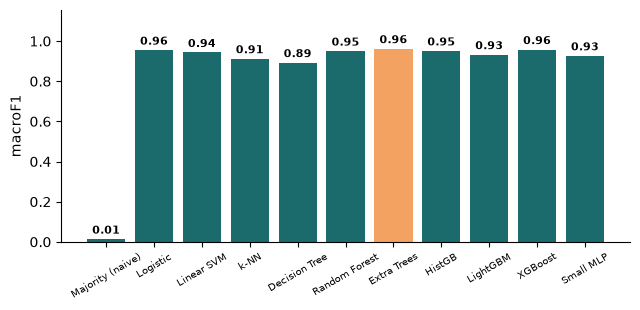

In [4]:
import matplotlib.pyplot as plt
def bar_chart(labels, values, ylabel, path, highlight=None, fmt='{:.1f}'):
    fig, ax = plt.subplots(figsize=(6.5, 3.2))
    colors = ['#F4A261' if i == highlight else '#1B6B6D' for i in range(len(values))]
    bars = ax.bar([str(l) for l in labels], values, color=colors)
    ax.bar_label(bars, labels=[fmt.format(v) for v in values], fontweight='bold', padding=2, fontsize=8 if len(values) > 7 else 10)
    ax.set_ylabel(ylabel); ax.set_ylim(0, max(values) * 1.2)
    ax.spines[['top', 'right']].set_visible(False)          # no top and right spines
    if len(values) > 7: ax.tick_params(axis='x', labelsize=7, rotation=30)
    fig.tight_layout(); fig.savefig(path, dpi=300); plt.show()

bar_chart(res.model, res.iloc[:, 1], res.columns[1], 'report/fig_rq2_models.png', highlight=int(res.iloc[:, 1].idxmax()), fmt='{:.2f}')

## Bước 6b. Câu hỏi thứ ba (RQ3)

- **Làm gì:** chạy năm phương pháp giải thích trên cùng một mô hình LightGBM và kiểm chứng chúng theo giao thức của đề tài: (1) ROAR với ba seed, (2) tỷ trọng theo vị trí đeo so với huấn luyện lại bằng một vị trí và bỏ một vị trí (LOSO trên 10 người), (3) ổn định xếp hạng giữa hai nhóm người không trùng nhau.
- **Vì sao dùng LightGBM:** TreeSHAP và split gain chỉ chạy trên mô hình cây tăng cường, nên năm phương pháp phải dùng chung LightGBM để so sánh công bằng; trong bài cần nói rõ LightGBM không phải mô hình có macro-F1 cao nhất ở RQ2. Thiết bị ở ngực gồm cả gia tốc và hai đạo trình ECG, nên phép "bỏ ngực" bỏ cả hai.
- **Kiểm tra:** hàng Random phải kém hơn các phương pháp giải thích; chênh lệch giữa hai phương pháp nhỏ hơn `retrained_sd` thì chưa được kết luận phương pháp nào trung thực hơn. Mỗi bảng `report/table_rq3_*.csv` ứng với một ý trong mục Results.

In [5]:
# Step 6b: RQ3, is an explanation confirmed after retraining without the blamed features, and which body position can be dropped?
import shap
from sklearn.linear_model import Ridge
from sklearn.inspection import permutation_importance
from scipy.stats import spearmanr
def fit_best(X, y, seed=0):
    return LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, subsample=0.8, subsample_freq=1,
                    colsample_bytree=0.8, random_state=seed, verbose=-1).fit(X, y)
def out(m, Z): return m.predict_proba(pd.DataFrame(Z, columns=m.feature_name_))          # model output on a raw array
def pool(sv, cols):                                     # mean absolute attribution per feature, classes pooled
    if isinstance(sv, list): sv = np.stack(sv, axis=-1)                 # older shap returns one array per class
    sv = np.abs(np.asarray(sv)); return sv.mean(axis=0) if sv.ndim == 2 else sv.mean(axis=(0, 2))
def r_tree_shap(m, X, y, n=200): return pool(shap.TreeExplainer(m).shap_values(X.sample(min(n, len(X)), random_state=0)), X.columns)
def r_kernel_shap(m, X, y, n=50):                       # model-agnostic SHAP, 20 k-means background points
    np.random.seed(0)                                   # KernelSHAP samples coalitions with numpy's global generator
    ex = shap.KernelExplainer(lambda Z: out(m, Z), shap.kmeans(X_tr[X.columns], 20))
    return pool(ex.shap_values(X.sample(n, random_state=0), nsamples=300, silent=True), X.columns)
def r_lime(m, X, y, n=50, n_pert=500):                  # LIME procedure (Ribeiro et al., 2016) written out, no extra package
    rs = np.random.RandomState(0); sd = X_tr[X.columns].std().to_numpy() + 1e-9; w = np.zeros(X.shape[1])
    for x in X.sample(n, random_state=0).to_numpy():
        Z = x + rs.randn(n_pert, len(x)) * sd           # perturb around one row
        P = out(m, Z); p = P[:, out(m, x[None]).argmax()]            # probability of the predicted class
        d = np.sqrt((((Z - x) / sd) ** 2).sum(1)); k = np.exp(-d ** 2 / (0.75 * np.sqrt(len(x))) ** 2)
        w += np.abs(Ridge(alpha=1.0).fit((Z - x) / sd, p, sample_weight=k).coef_)    # weighted local linear surrogate
    return w / n
def r_perm(m, X, y, n=3000):                            # loss of score when one feature is shuffled
    Xv = X.sample(min(n, len(X)), random_state=0)
    return permutation_importance(m, Xv, y.loc[Xv.index], n_repeats=3, scoring='f1_macro', random_state=0).importances_mean
def r_gain(m, X, y): return m.booster_.feature_importance('gain')      # built-in split gain of LightGBM
METHODS = {'TreeSHAP': r_tree_shap, 'KernelSHAP': r_kernel_shap, 'LIME': r_lime, 'Permutation': r_perm, 'Gain': r_gain}
def explain_all(m, cols):                               # one ranking per method plus the time each one takes
    R, secs = {}, {}
    for name, f in METHODS.items():
        t0 = time.perf_counter(); R[name] = pd.Series(f(m, X_te[cols], y_te), index=cols).sort_values(ascending=False)
        secs[name] = time.perf_counter() - t0
    return R, secs
def score(m, X): return f1_score(y_te, m.predict(X), average='macro')
SEEDS = [0, 1, 2]                                       # every retraining is repeated with three seeds
best = fit_best(X_tr, y_tr); ranks, secs = explain_all(best, X_cols)
bases = [score(fit_best(X_tr, y_tr, seed=s), X_te) for s in SEEDS]; base = np.mean(bases)
ranks['Random'] = pd.Series(np.random.RandomState(0).rand(len(X_cols)), index=X_cols).sort_values(ascending=False)
# (1) remove the k top-ranked features: score without retraining (deletion) and after retraining (ROAR)
KS = [k for k in [1, 3, 6, 10] if k < len(X_cols)]; rows = []
for name, r in ranks.items():
    for k in KS:
        top = list(r.index[:k]); keep = [c for c in X_cols if c not in top]
        Xp = X_te.copy(); Xp[top] = X_tr[top].mean().values
        rt = [score(fit_best(X_tr[keep], y_tr, seed=s), X_te[keep]) for s in SEEDS]
        rows.append([name, k, score(best, Xp), np.mean(rt), np.std(rt)])
roar = pd.DataFrame(rows, columns=['method', 'k', 'deleted', 'retrained', 'retrained_sd']); roar.to_csv('report/table_rq3_roar.csv', index=False)
print('score with all features', round(base, 3), '+-', round(np.std(bases), 3))
print(roar.pivot(index='method', columns='k', values='retrained').round(3)); print(roar.pivot(index='method', columns='k', values='retrained_sd').round(3))
# (2) feature groups: share of attribution per method against the score after retraining on one group only
share = pd.DataFrame({k: (r.clip(lower=0) / r.clip(lower=0).sum()).groupby(GROUP).sum() for k, r in ranks.items() if k != 'Random'})
share.to_csv('report/table_rq3_group_share.csv'); print(share.round(3))
dev = GROUP.replace({'heart signal': 'chest'})          # the ECG leads sit on the chest device
pick = lambda keep: list(GROUP.index[keep])
SETS = {'all': X_cols, 'only chest acc': pick(GROUP == 'chest'), 'only chest device (acc + ECG)': pick(dev == 'chest'),
        'only ankle': pick(GROUP == 'ankle'), 'only wrist': pick(GROUP == 'wrist'), 'only heart signal': pick(GROUP == 'heart signal'),
        'drop chest device': pick(dev != 'chest'), 'drop ankle': pick(GROUP != 'ankle'), 'drop wrist': pick(GROUP != 'wrist')}
pos = []
for sname, c in SETS.items():                           # retrain on a subset of positions, leave-one-subject-out over 10 people
    for s_out in people:
        tr, te = subj != s_out, subj == s_out
        m = fit_best(X_all.loc[tr, c], y_all[tr]); pos.append([sname, s_out, f1_score(y_all[te], m.predict(X_all.loc[te, c]), average='macro')])
pos = pd.DataFrame(pos, columns=['setting', 'held_out', 'macroF1'])
pos_tab = pos.groupby('setting', sort=False).macroF1.agg(['mean', 'std', 'min']).reset_index()
pos_tab.to_csv('report/table_rq3_positions.csv', index=False); print(pos_tab.round(3))
# (3) stability: the ranking of the same method when the model is trained on two disjoint sets of people
rA, _ = explain_all(fit_best(X_tr[GRP_A], y_tr[GRP_A], seed=1), X_cols)
rB, _ = explain_all(fit_best(X_tr[GRP_B], y_tr[GRP_B], seed=2), X_cols)
stab = pd.Series({k: spearmanr(rA[k][X_cols], rB[k][X_cols])[0] for k in rA}); print(stab.round(3))
pd.DataFrame({'rank_stability': stab, 'seconds': pd.Series(secs)}).to_csv('report/table_rq3_methods.csv')

score with all features 0.947 +- 0.001
k               1      3      6      10
method                                 
Gain         0.949  0.939  0.939  0.948
KernelSHAP   0.940  0.935  0.935  0.912
LIME         0.940  0.944  0.912  0.933
Permutation  0.940  0.919  0.945  0.907
Random       0.947  0.947  0.947  0.950
TreeSHAP     0.940  0.935  0.935  0.932
k               1      3      6      10
method                                 
Gain         0.000  0.002  0.009  0.013
KernelSHAP   0.002  0.007  0.005  0.014
LIME         0.002  0.002  0.003  0.001
Permutation  0.002  0.006  0.012  0.002
Random       0.001  0.001  0.002  0.001
TreeSHAP     0.002  0.007  0.005  0.002
              TreeSHAP  KernelSHAP   LIME  Permutation   Gain
ankle            0.401       0.389  0.392        0.486  0.345
chest            0.231       0.230  0.218        0.231  0.276
heart signal     0.003       0.018  0.049        0.001  0.001
wrist            0.365       0.362  0.341        0.282  0.379


                         setting   mean    std    min
0                            all  0.934  0.051  0.867
1                 only chest acc  0.786  0.096  0.631
2  only chest device (acc + ECG)  0.782  0.090  0.643
3                     only ankle  0.792  0.121  0.559
4                     only wrist  0.749  0.112  0.533
5              only heart signal  0.118  0.040  0.053
6              drop chest device  0.894  0.060  0.809
7                     drop ankle  0.851  0.084  0.742
8                     drop wrist  0.865  0.101  0.748


TreeSHAP       0.521
KernelSHAP     0.558
LIME           0.464
Permutation    0.296
Gain           0.608
dtype: float64


## Bước 6c. Đối chiếu và bảng tham số

- **Làm gì:** đặt kết quả các phương pháp cạnh nhau, lưu hình SHAP và tham số mô hình.
- **Vì sao:** bảng tham số và danh sách đặc trưng đứng đầu đi vào phụ lục của bài.
- **Kiểm tra:** `report/params_best.json` tồn tại.

In [6]:
# Step 6c: what the methods say side by side, and the selected parameter table
import json, matplotlib.pyplot as plt
top = pd.DataFrame({k: r.index[:10] for k, r in ranks.items() if k != 'Random'})
top.to_csv('report/table_top10_by_method.csv', index=False); print(top.head(5))
votes = pd.Series([f for k, r in ranks.items() if k != 'Random' for f in r.index[:5]]).value_counts()
votes.rename('methods_listing_in_top5').to_csv('report/table_consensus_features.csv'); print(votes.head(8))
print(share.round(3))                                   # do the methods blame the same body position? (table_rq3_group_share.csv)
Xs = X_te.sample(min(500, len(X_te)), random_state=0)
shap.summary_plot(shap.TreeExplainer(best).shap_values(Xs), Xs, show=False, plot_type='bar')
plt.savefig('report/fig_shap.png', dpi=300, bbox_inches='tight'); plt.close()
with open('report/params_best.json', 'w', encoding='utf-8') as f: json.dump(best.get_params(), f, indent=2, default=str)   # parameter table

           TreeSHAP        KernelSHAP              LIME       Permutation  \
0  ankle_acc_y_mean  ankle_acc_y_mean  ankle_acc_y_mean  ankle_acc_y_mean   
1  chest_acc_x_mean  chest_acc_x_mean  chest_acc_z_mean  wrist_acc_y_mean   
2  ankle_accmag_std  ankle_accmag_std  chest_acc_x_mean  chest_acc_x_mean   
3  wrist_acc_y_mean  wrist_acc_y_mean  ankle_accmag_std  ankle_accmag_std   
4  chest_acc_z_mean  chest_acc_z_mean  wrist_acc_y_mean  wrist_accmag_std   

                Gain  
0   chest_acc_z_mean  
1  ankle_accmag_mean  
2   ankle_acc_y_mean  
3   chest_acc_x_mean  
4   wrist_acc_y_mean  
ankle_acc_y_mean     5
chest_acc_x_mean     5
wrist_acc_y_mean     5
ankle_accmag_std     4
chest_acc_z_mean     4
wrist_accmag_std     1
ankle_accmag_mean    1
Name: count, dtype: int64
              TreeSHAP  KernelSHAP   LIME  Permutation   Gain
ankle            0.401       0.389  0.392        0.486  0.345
chest            0.231       0.230  0.218        0.231  0.276
heart signal     0.003    

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_8044\2062056981.py:9: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap.TreeExplainer(best).shap_values(Xs), Xs, show=False, plot_type='bar')


## Test case và chẩn đoán

- **Làm gì:** kiểm tra tự động các sản phẩm của notebook.
- **Kiểm tra:** mọi `assert` qua. Sinh viên A chạy lại notebook này và ghi vào ô Đối chứng.

In [7]:
import glob
assert os.path.exists('report/table_rq2.csv') and os.path.exists('report/params_best.json')
assert all(os.path.exists('report/table_rq3_%s.csv' % t) for t in ['roar', 'group_share', 'methods', 'positions']), 'RQ3 tables missing'
assert res.macroF1.notna().all()
top = res.sort_values('macroF1').iloc[-1]
assert top.macroF1 > res.set_index('model').loc['Majority (naive)', 'macroF1'], 'the best model must beat the naive baseline'
print('best model', top.model, round(top.macroF1, 3), '+-', round(top.sd, 3))
print(sorted(os.path.basename(f) for f in glob.glob('report/*')))
print('Notebook B: all checks passed')

best model Extra Trees 0.962 +- 0.048
['fig_pipeline_overview.png', 'fig_pipeline_overview.svg', 'fig_pipeline_overview_cute.png', 'fig_pipeline_overview_cute.svg', 'fig_rq1.png', 'fig_rq2_models.png', 'fig_shap.png', 'params_best.json', 'table_cleaning_log.csv', 'table_consensus_features.csv', 'table_group_share.csv', 'table_q1.csv', 'table_q2.csv', 'table_q3.csv', 'table_q4.csv', 'table_q5.csv', 'table_rq1_tests.csv', 'table_rq2.csv', 'table_rq2_folds.csv', 'table_rq3_group_share.csv', 'table_rq3_methods.csv', 'table_rq3_positions.csv', 'table_rq3_roar.csv', 'table_top10_by_method.csv']
Notebook B: all checks passed


### Đối chứng

| Người chạy lại | Ngày | Metric chính khớp | Ghi chú |
|---|---|---|---|
| | | | |

### Chẩn đoán

Nếu mô hình tốt nhất không hơn mốc đơn giản hoặc kết quả RQ3 trái dự kiến, ghi nguyên nhân có bằng chứng (thiếu đặc trưng, dữ liệu ít, lệch giữa hai tập) vào `report/table_diagnosis.csv`.

### Báo cáo tiến độ

1. Việc đã xong, kèm tên file và số dòng, bảng, hình:
2. Con số chính mới có:
3. Vướng mắc và điều đã thử:
4. Việc sẽ làm đến lần báo cáo sau, ai làm:
5. Prompt AI đáng chú ý và Human Delta: